<h1 style="color: #4166c4; font-weight: 700;">Sentiment Analysis</h1>

## Table of Contents

- [1. Introduction](#introduction)
- [2. Data preparation](#data-preparation)
  - [2.1 Load the data](#load-data)
- [3. Lyrics cleaning and language filtering](#lyrics-cleaning)
- [4. Sentiment scoring](#sentiment-scoring)
  - [4.1 Line-level scores](#line-level-scores)
  - [4.2 Song-level scores and tool agreement](#song-level-scores)
- [5. Sentiment patterns](#sentiment-patterns)
  - [5.1 Genre, artist, and decade](#metadata)
  - [5.2 Within-song arc](#song-arc)
- [6. Sentiment over time](#time-trends)
- [7. Themes and emotions](#themes-emotions)
- [8. Subjectivity](#subjectivity)
- [9. Validation and robustness](#validation)
- [10. Discussion and conclusions](#discussion)

<h2 style="color: #4166c4; font-weight: 400;">1. Introduction <a id="introduction"></a></h2>

This notebook compares VADER and TextBlob sentiment estimates for song lyrics. Both methods use general-purpose English lexicons, so their outputs are exploratory signals rather than human-labelled ground truth. The analysis uses a reproducible sample from each genre. Data cleaning, scoring, summaries, plots, and validation are implemented in `tools/sentiment_analysis.py`; notebook cells call those helpers and present the results.

<h2 style="color: #4166c4; font-weight: 400;">2. Data preparation <a id="data-preparation"></a></h2>

### 2.1 Load the data <a id="load-data"></a>

The loader checks that the fields used below are present. The original lyrics remain unchanged in `df_train`; all text cleaning happens in a separate `lyrics_clean` column.

In [4]:
pip install nrclex

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 624.3/624.3 kB 7.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nrclex]2m3/4 [nrclex]
Note: you may need to restart the kernel to use updated packages.


In [5]:
from pathlib import Path
import importlib
import sys

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data").is_dir() and (path / "tools").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing data/ and tools/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import tools.sentiment_analysis as sentiment
sentiment = importlib.reload(sentiment)

from IPython.display import display

df_train = sentiment.load_data(PROJECT_ROOT / "data" / "clean_train.csv")
print(f"Loaded {len(df_train):,} songs with {df_train.shape[1]} columns.")
print(f"Missing lyrics: {df_train['lyrics'].isna().sum():,}")
print(f"Repeated lyric rows: {df_train['lyrics'].duplicated(keep=False).sum():,}")
display(df_train[["title", "tag", "artist", "year", "lyrics"]].head(2))

Loaded 107,746 songs with 8 columns.
Missing lyrics: 0
Repeated lyric rows: 0


,title,tag,artist,year,lyrics
0,But How? Jesus Pizzas,pop,Grip Grand,2015.0,"Jesus, the beat is cut in pieces like pizzas\n..."
1,Substance Therapy,rap,REMI,2016.0,[Refrain]\nAnd now blow your money\nAnd there ...


<h2 style="color: #4166c4; font-weight: 400;">3. Lyrics cleaning and language filtering <a id="lyrics-cleaning"></a></h2>

Section labels such as `[Chorus]` and `[Verse 1]`, common contributor credits, and obvious scrape prompts are removed. Punctuation, capitalization, negations, contractions, and slang are preserved because they can affect sentiment scores.

The main analysis removes exact repeated lines (ignoring capitalization) so a repeated chorus does not outweigh the rest of the song.
A second version keeps repeated lines for a robustness check. Language detection is applied to sampled, cleaned lyrics, retaining only English predictions with at least 80% confidence are retained. While this method may identify the dominant language, it may miss individual code-switched lines.

In [6]:
df_candidates, df_sample, language_counts = sentiment.prepare_sample(df_train)

print("Detected languages in the sample before filtering:")
display(language_counts)
print(
    f"Retained {len(df_sample):,} English songs at confidence >= "
    f"{sentiment.LANGUAGE_CONFIDENCE:.0%} from {len(df_candidates):,} sampled songs."
)
print(
    "Repeated lyrics remain separate dataset records. Repeated lines within each "
    "song are removed only in the primary scoring version."
)
display(
    df_sample[
        ["title", "tag", "language", "language_confidence", "lyrics", "lyrics_clean"]
    ].head(2)
)

Detected languages in the sample before filtering:


,songs
language,
en,2149
fr,1
ca,1
nl,1
cy,1
tl,1


Retained 2,145 English songs at confidence >= 80% from 2,154 sampled songs.
Repeated lyrics remain separate dataset records. Repeated lines within each song are removed only in the primary scoring version.


,title,tag,language,language_confidence,lyrics,lyrics_clean
0,Two Frequencies,country,en,0.999995,I just think it's funny\nThe way the lights al...,I just think it's funny\nThe way the lights al...
1,Baby Be Crazy,country,en,0.999997,"[Verse 1]\nWell, you know they say\nThey say t...","Well, you know they say\nThey say that I'm a r..."


<h2 style="color: #4166c4; font-weight: 400;">4. Sentiment scoring <a id="sentiment-scoring"></a></h2>

Every cleaned line in every song is scored by VADER and TextBlob.
In VADER, the original text based on grammar and a specific lexicon is analysed, while in TextBlob we calculate polarity and subjectivity. Then, the tool outputs line-by-line scores (including duplicate lines) alongside the overall song averages.

### 4.1 Line-level Scores <a id="line-level-scores"></a>


In [ ]:
df_lines, df_song = sentiment.score_lyric_lines(df_sample)
print(f"Scored {len(df_lines):,} lyric lines across both versions.")
display(df_lines.head())

Scored 155,861 lyric lines across both versions.


,song_key,line_version,line_index,line_position,line_text,vader_neg,vader_neu,vader_pos,vader_compound,textblob_polarity,textblob_subjectivity,vader_label,textblob_label
0,0,all_lines,0,0.000000,I just think it's funny,0.0,0.58,0.42,0.4404,0.25,1.0,Positive,Positive
1,0,all_lines,1,0.021277,The way the lights all turn green,0.0,1.00,0.00,0.0000,-0.20,0.3,Neutral,Negative
2,0,all_lines,2,0.042553,As I'm driving to your house,0.0,1.00,0.00,0.0000,0.00,0.0,Neutral,Neutral
3,0,all_lines,3,0.063830,I just think it's funny,0.0,0.58,0.42,0.4404,0.25,1.0,Positive,Positive
4,0,all_lines,4,0.085106,How many times you texted me,0.0,1.00,0.00,0.0000,0.50,0.5,Neutral,Positive


### 4.2 Song-level scores and tool agreement <a id="song-level-scores"></a>

The song score is the mean of its line scores, so every retained line contributes equally within a song. 
The primary summaries use the repeated-line-deduplicated version. 

Agreement measures describe similarity between the tools, not accuracy against human judgements.

,VADER,TextBlob
sentiment,,
Negative,0.245221,0.117949
Neutral,0.369697,0.565967
Positive,0.385082,0.316084


Spearman correlation (VADER vs TextBlob): 0.606
Label agreement: 55.3%
Cohen's kappa: 0.302


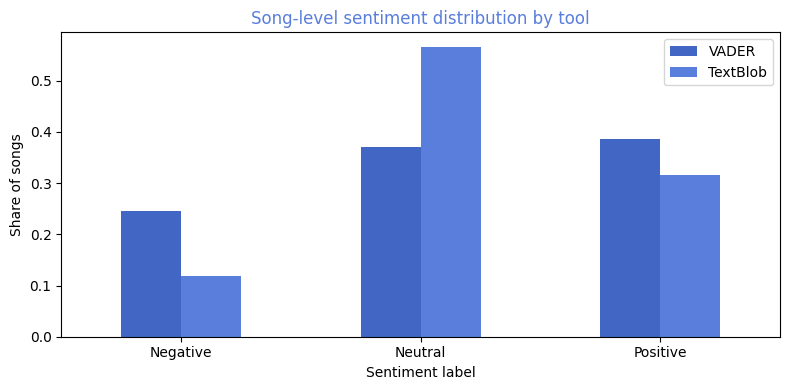

In [8]:
df_song_primary = df_song[df_song["line_version"].eq("deduplicated")].copy()
distribution, agreement = sentiment.get_sentiment_agreement(df_song_primary)
display(distribution.rename_axis("sentiment"))
print(f"Spearman correlation (VADER vs TextBlob): {agreement['spearman_correlation']:.3f}")
print(f"Label agreement: {agreement['label_agreement']:.1%}")
print(f"Cohen's kappa: {agreement['cohen_kappa']:.3f}")
sentiment.plot_sentiment_distribution(distribution)

<h2 style="color: #4166c4; font-weight: 400;">5. Sentiment patterns <a id="sentiment-patterns"></a></h2>

### 5.1 Genre, artist, and decade <a id="metadata"></a>

The following summaries give each song equal weight.

Artist averages include artists with at least three sampled songs and, decade averages include plausible release years and decades with at least ten sampled songs.

,song_count,vader_mean,textblob_mean,positive_share
tag,,,,
rap,616,-0.029059,0.004572,0.232143
rock,402,0.002521,0.015570,0.310945
pop,885,0.043458,0.037337,0.497175
misc,90,0.046141,0.034263,0.411111
rb,97,0.056093,0.042841,0.494845
country,55,0.075668,0.060154,0.600000


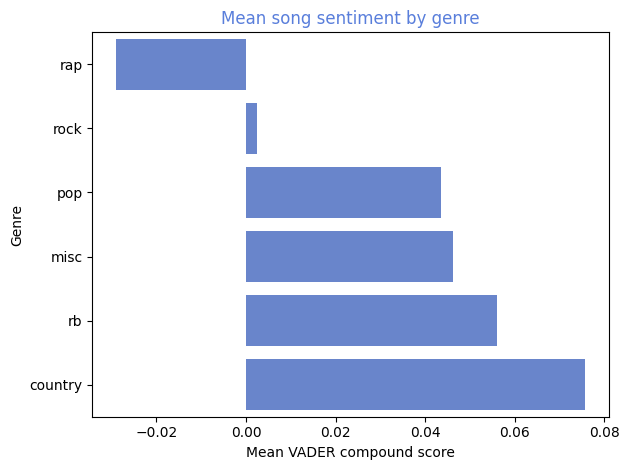

Artists with the most sampled songs:


,song_count,vader_mean,textblob_mean
artist,,,
Bing Crosby,3,0.148350,0.050493
Emily Dickinson,3,0.024347,-0.024679


Sentiment by decade:


,song_count,vader_median,textblob_median
decade,,,
1960.0,26,0.079018,0.061824
1970.0,38,0.066395,0.052266
1980.0,66,0.076815,0.039608
1990.0,133,0.044029,0.027922
2000.0,291,0.016193,0.023333
2010.0,1118,0.013184,0.017758
2020.0,458,0.009548,0.016324


In [9]:
genre_summary, artist_summary, decade_summary = sentiment.summarize_metadata(
    df_song_primary
)
display(genre_summary)
sentiment.plot_genre_sentiment(genre_summary)
print("Artists with the most sampled songs:")
display(artist_summary.sort_values("song_count", ascending=False).head(15))
print("Sentiment by decade:")
display(decade_summary)

### 5.2 Within-song arc <a id="song-arc"></a>

To map the emotional arc, each song is split chronologically into ten equal parts (bins). We average the scores within each part for every song, then average them across all songs. This prevents longer tracks from distorting the overall trend.

,vader_compound,textblob_polarity
position_bin,,
0,0.005479,0.013505
1,0.018122,0.024121
2,0.016768,0.024125
3,0.019772,0.030953
4,0.017307,0.021486
5,0.021049,0.022833
6,0.010961,0.027862
7,0.019128,0.024535
8,0.028108,0.032155


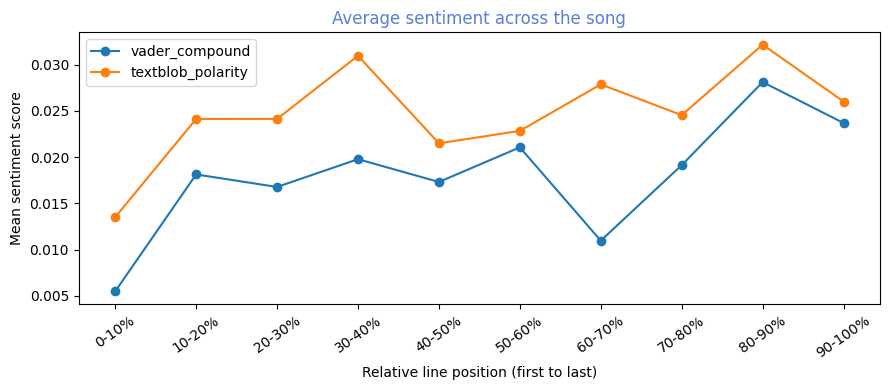

In [10]:
arc_summary = sentiment.summarize_song_arc(df_lines)
display(arc_summary)
sentiment.plot_song_arc(arc_summary)

<h2 style="color: #4166c4; font-weight: 400;">6. Sentiment over time <a id="time-trends"></a></h2>

Years outside 1900–2024 are excluded as implausible for this dataset. Annual medians are shown only for years with at least eight sampled songs. The five-year rolling median uses calendar years, so missing years are not treated as adjacent observations.

Songs excluded for implausible release years: 6


,song_count,vader_median,textblob_median,vader_rolling_median
year,,,,
2013,102.0,0.000000,0.018151,0.019808
2014,95.0,0.019808,0.021256,0.015676
2015,170.0,0.043968,0.023265,0.015676
2016,78.0,0.015676,0.013617,0.015676
2017,151.0,0.014581,0.017893,0.014581
2018,191.0,-0.006033,0.014658,0.010867
2019,196.0,0.010867,0.014755,0.009643
2020,233.0,0.009643,0.015000,0.009643
2021,194.0,0.004704,0.015536,0.010255


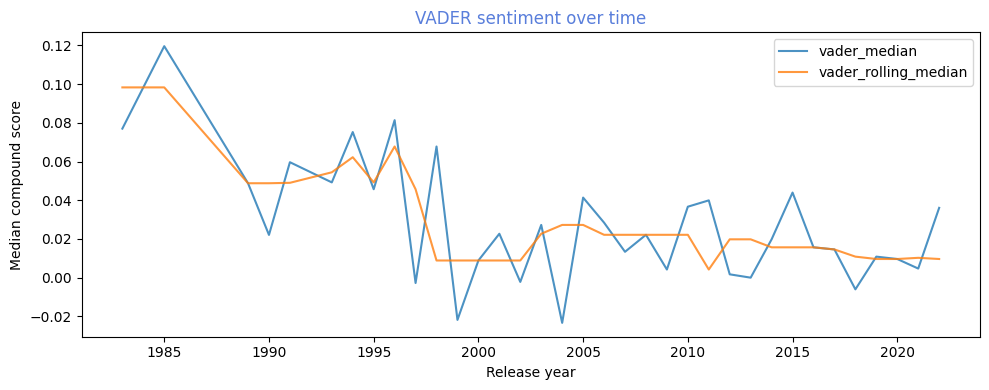

In [11]:
year_summary, excluded_years = sentiment.summarize_sentiment_over_time(
    df_song_primary
)
print(f"Songs excluded for implausible release years: {excluded_years:,}")
display(year_summary.tail(10))
sentiment.plot_sentiment_over_time(year_summary)

<h2 style="color: #4166c4; font-weight: 400;">7. Themes and emotions <a id="themes-emotions"></a></h2>

TF-IDF and Non-Negative Matrix Factorization (NMF) are applied to extract exploratory topics from lyrics, while the NRC Lexicon calculates emotion proportions across genres. TF-IDF weights word importance within each song, allowing NMF to cluster text into statistical topic groups. These outputs represent high-weight keywords rather than verified theme labels. Similarly, the NRC Lexicon tracks emotional distributions via direct word-matching frequencies. These metrics reflect literal textual data rather than psychological assessments of the authors.

Exploratory topics:


,,song_count,vader_mean,textblob_mean
topic_id,topic_terms,,,
4,"time, life, away, it's, world, come, day, like",800,0.011808,0.022832
1,"bitch, niggas, nigga, fuck, shit, like, ain't, got",366,-0.064356,-0.008329
0,"don't, yeah, know, wanna, just, want, baby, don't wanna",325,0.030543,0.028022
5,"i'm, like, just, it's, i'll, can't, cause, that's",280,0.016659,0.018109
3,"love, love love, baby, heart, you're, know, forever, want",226,0.117091,0.074886
2,"oh, oh oh, yeah, oh yeah, baby, she's, ohh, beautiful",148,0.056646,0.042888


NRC emotion proportions by genre:


,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
tag,,,,,,,,
country,0.052529,0.100151,0.040188,0.065233,0.134375,0.085265,0.054854,0.110982
misc,0.053619,0.143045,0.044955,0.078413,0.084792,0.073193,0.039109,0.107072
pop,0.060168,0.106579,0.041435,0.085320,0.111846,0.094138,0.050547,0.097081
rap,0.100211,0.079119,0.077783,0.102054,0.074960,0.094080,0.044722,0.087289
rb,0.066770,0.098749,0.039651,0.077398,0.122160,0.090160,0.053537,0.093404
rock,0.070613,0.102843,0.053395,0.102503,0.087358,0.099058,0.046984,0.091696


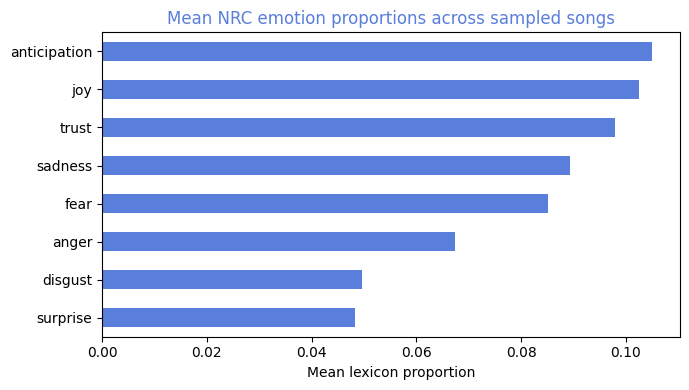

In [12]:
theme_summary, emotion_summary = sentiment.summarize_themes_and_emotions(
    df_sample, df_song_primary
)
print("Exploratory topics:")
display(theme_summary)
print("NRC emotion proportions by genre:")
display(emotion_summary)
sentiment.plot_emotions(emotion_summary)

<h2 style="color: #4166c4; font-weight: 400;">8. Subjectivity <a id="subjectivity"></a></h2>

TextBlob subjectivity is the mean of the line-level subjectivity scores. Lyrics are expected to be subjective, so a high or narrow distribution does not establish that the sentiment estimates are accurate.

,textblob_subjectivity
count,2145.000000
mean,0.214720
std,0.098433
min,0.000000
25%,0.146175
50%,0.204545
75%,0.270238
max,0.633333


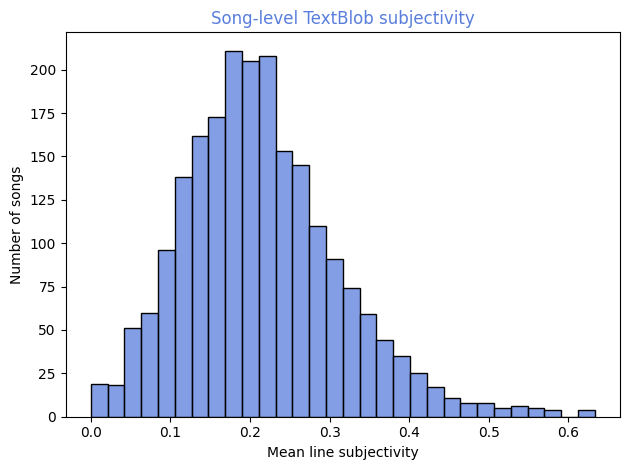

In [13]:
subjectivity_summary = sentiment.summarize_subjectivity(df_song_primary)
display(subjectivity_summary.to_frame("textblob_subjectivity"))
sentiment.plot_subjectivity(df_song_primary)

<h2 style="color: #4166c4; font-weight: 400;">9. Validation and robustness <a id="validation"></a></h2>

The dataset has no human sentiment labels, so validation consists of simple cleaning checks, inspection of example scores, comparison between tools, and a repeated-chorus sensitivity check. Review ambiguous language predictions before making language-specific claims.

In [14]:
cleaning_example = sentiment.validate_cleaning()
print("Cleaning checks passed. Example cleaned text:")
print(cleaning_example)

print("Example line scores:")
display(sentiment.score_validation_examples())

chorus_sensitivity = sentiment.summarize_chorus_sensitivity(df_song)
display(
    chorus_sensitivity[["absolute_score_change", "label_changed"]].describe(
        include="all"
    )
)
print(
    "Songs whose VADER label changes when repeated lines are kept: "
    f"{chorus_sensitivity['label_changed'].mean():.1%}"
)

ambiguous_language = df_candidates[
    ~(
        df_candidates["language"].eq("en")
        & df_candidates["language_confidence"].ge(sentiment.LANGUAGE_CONFIDENCE)
    )
].sort_values("language_confidence")
display(
    ambiguous_language[
        ["title", "artist", "language", "language_confidence"]
    ].head(10)
)

Cleaning checks passed. Example cleaned text:
I DON'T want to go!!!
Maybe tomorrow...
Example line scores:


,line,vader_compound,textblob_polarity
0,I love this song!,0.6696,0.625
1,I do not love this song.,-0.5216,-0.250
2,I NEVER said I hated you!!!,0.6421,-1.000
3,I'm gonna be alright...,0.2500,0.000


line_version,absolute_score_change,label_changed
count,2145.000000,2145
unique,NaN,2
top,NaN,False
freq,NaN,1875
mean,0.024102,NaN
std,0.033768,NaN
min,0.000000,NaN
25%,0.001975,NaN
50%,0.012863,NaN
75%,0.032515,NaN


Songs whose VADER label changes when repeated lines are kept: 12.6%


,title,artist,language,language_confidence
92980,Sha-La Love You,Lancelot Link and the Evolution Revolution,ca,0.571426
29998,Enter In,The Blackbyrds,nl,0.571427
67624,You said,Iriss,cy,0.571427
77497,Dark Knight,OCTOBERSFULLMOON,en,0.714283
461,Chemicals,The Paperviews,tl,0.714284
75111,Bug Bites,Del Water Gap,en,0.714285
105699,Run,Air,en,0.714285
104532,Peng,Sama Blake,en,0.714286
104995,Never Let You Go,LEV in the Wild,fr,0.857141


<h2 style="color: #4166c4; font-weight: 400;">10. Discussion and conclusions <a id="discussion"></a></h2>

Use the results above to discuss which genres and decades have higher or lower scores, how closely VADER and TextBlob agree, whether the average within-song arc is consistent, and how much repeated lines change the results. Describe prominent topic terms and emotions as exploratory signals.

The analysis is limited by general-purpose English lexicons, language-detection errors, irony, metaphor, dialect, genre-specific slang, and scraping noise. The genre-stratified sample may still be sparse by artist and year. Do not treat the scores as objective emotional truth or infer causation from group differences.

In [15]:
print(
    f"Analyzed {df_song_primary['song_key'].nunique():,} high-confidence English songs "
    f"and {len(df_lines):,} line instances."
)
print(
    f"Mean song scores: VADER={df_song_primary['vader_compound'].mean():.3f}, "
    f"TextBlob={df_song_primary['textblob_polarity'].mean():.3f}."
)
print(
    f"Tool agreement: Spearman rho={agreement['spearman_correlation']:.3f}; "
    f"label agreement={agreement['label_agreement']:.1%}; "
    f"kappa={agreement['cohen_kappa']:.3f}."
)

Analyzed 2,145 high-confidence English songs and 155,861 line instances.
Mean song scores: VADER=0.016, TextBlob=0.025.
Tool agreement: Spearman rho=0.606; label agreement=55.3%; kappa=0.302.


The evaluation of 2,145 songs confirms a strong correlation (Spearman rho=0.606) alongside a fair categorical consensus between both models. Label agreement (55.3%) tracks how often both tools assign the exact same category, while the Kappa score (0.302) proves this consensus is statistically meaningful by discounting random chance. Ultimately, this cross-tool reliability validates that both algorithms follow the same emotional trajectories, with minor discrepancies stemming from their architectures: VADER uses syntactic rules for informal text, whereas TextBlob relies strictly on formal dictionary adjectives.